# COVID-19 in Madrid

## Introduction

On March 13, after the outbreak of COVID-19 in Spain, the central government in Madrid [declared the state of alarm](https://english.elpais.com/society/2020-03-15/spains-state-of-alarm-the-key-measures-that-are-now-in-place.html). Under this state, the movements of citizens will be very limited. This decree will affect the whole of Spain during 15 days although, to be honest, it will probably take longer. Motivated by [previous articles](https://www.businessinsider.com/quarantines-air-pollution-china-but-wont-last-for-long-expert-2020-3?IR=T) on the decreased pollution that has been observed in China, I want to see if our lockdown will have a similar impact in our air quality.

The aim of this project is to analyse air quality parameters day by day since March 12. I am going to extend this project as much as possible, so I can also observe how long it takes us to get Madrid back to our usual pollution levels. My hope is to provide people with enough data to make them think about the impact of our habits in our environment.

Although there are plenty of online visualisation tools availble (like [this one](https://airindex.eea.europa.eu/Map/AQI/Viewer/) developed by the European Environment Agency, aka EEA), to me this was the perfect chance to get used to Pandas and Matplotlib again, with a little bit of Bash scripting.

## Assessing the air quality

### Materials

I reused an old laptop (Asus EeePC 1001PX) that was lying around in my appartment and installed Lubuntu 16.04.6 LTS.

### Getting the data

I wrote a Bash script (*data_script.sh*) that sends a request to the servers of Madrid city hall to get the daily [air quality data](https://datos.madrid.es/portal/site/egob/menuitem.c05c1f754a33a9fbe4b2e4b284f1a5a0/?vgnextoid=aecb88a7e2b73410VgnVCM2000000c205a0aRCRD&vgnextchannel=374512b9ace9f310VgnVCM100000171f5a0aRCRD&vgnextfmt=default) as a CSV file.

As I didn't want to do this manually, I added my script to [crontab](https://www.computerhope.com/unix/ucrontab.htm).

### Choose the data

I will primarily focus on famous places such as:

- 28079027 - Barajas
- 28079050 - Plaza de Castilla
- 28079048 - Paseo de la Castellana
- 28079038 - Cuatro Caminos
- 28079035 - Plaza de España
- 28079049 - Retiro
- 28079024 - Casa de Campo
- 28079058 - El Pardo

The magnitudes to be studied are the top five key pollutants, according to the EEA. The numbers shown are the pollutant IDs in our CSV files:

* 1 - SO2
* 8 - NO2
* 9 - PM2.5
* 10 - PM10
* 14 - O3

You can read all the information about this encoding in the PDF file (*Interprete_ficheros_calidad_del_aire_global*).

The bands of concentrations and index levels have been defined by WHO in the [HRAPIE project report](http://www.euro.who.int/en/health-topics/environment-and-health/air-quality/publications/2013/health-risks-of-air-pollution-in-europe-hrapie-project.-recommendations-for-concentrationresponse-functions-for-costbenefit-analysis-of-particulate-matter,-ozone-and-nitrogen-dioxide).

I find **Barajas** very interesting as it is close to the airport, which has significantly reduced the number of flights. I am also going to look at NO2 because [traffic and heating systems](https://www.madrid.es/portales/munimadrid/es/Inicio/Servicios-sociales-y-salud/Salud/Dioxido-de-nitrogeno-y-salud/?vgnextfmt=default&vgnextoid=7f9c7fb3af761510VgnVCM2000000c205a0aRCRD&vgnextchannel=0815c8eb248fe410VgnVCM1000000b205a0aRCRD) are the main sources of this pollutant.

Here is a [map](https://www.madrid.es/portales/munimadrid/es/Inicio/Medio-ambiente/Direcciones-y-telefonos/Estaciones-remotas-de-medicion-de-la-calidad-del-aire?vgnextfmt=default&vgnextoid=8c7c2a64e309a110VgnVCM2000000c205a0aRCRD&vgnextchannel=864f79ed268fe410VgnVCM1000000b205a0aRCRD) with all the sampling stations:

![title](mapa_completo_red.jpg)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import glob
import os
%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (11, 11)


check_places = {'28079027':'Barajas','28079050':'Plaza de Castilla','28079048':'Pº de la Castellana','28079038':'Cuatro Caminos','28079035':'Plaza de España', '28079049':'Retiro', '28079024':'Casa de Campo', '28079058':'El Pardo'}
# Now I am following the EEA and WHO
# measurements = {1:'SO2',6:'CO',7:'NO',8:'NO2', 9: 'PM2.5', 10:'PM10',12:'NOx',14:'O3',44:'NMHC'}
measurements = {1:'SO2',8:'NO2', 9: 'PM2.5', 10:'PM10',14:'O3'}
check_times = ['H01','H02','H03','H04','H05','H06','H07','H08','H09','H10','H11','H12','H13','H14','H15','H16','H17','H18','H19','H20','H21','H22','H23']
check_times_peak = ['H07','H08','H09','H10','H18','H19','H20','H21']
check_times_mid = ['H11','H12','H13','H14']

bands ={'SO2': {'Good': [0,100], 'Fair': [100,200], 'Moderate': [200,350], 'Poor': [350,500], 'Very poor': [500,750], 'Extremely poor': [750,1250]},
        'NO2': {'Good': [0,40], 'Fair': [40,90], 'Moderate': [90,120], 'Poor': [120,230], 'Very poor': [230,340], 'Extremely poor': [340,1000]},
        'PM2.5': {'Good': [0,10], 'Fair': [10,20], 'Moderate': [20,25], 'Poor': [25,50], 'Very poor': [50,75], 'Extremely poor': [75,800]},
        'PM10': {'Good': [0,20], 'Fair': [20,40], 'Moderate': [40,50], 'Poor': [50,100], 'Very poor': [100,150], 'Extremely poor': [150,1200]}, 
        'O3': {'Good': [0,50], 'Fair': [50,100], 'Moderate': [100,130], 'Poor': [130,240], 'Very poor': [240,380], 'Extremely poor': [380,800]}}

units = {'SO2': 'ug/m3',
        'NO2': 'ug/m3',
        'PM2.5': 'ug/m3',
        'PM10': 'ug/m3', 
        'O3': 'ug/m3'}


hours = range(1,25)

In [2]:
# Merge all the csv files in one data frame
files = glob.glob('air_data/*.csv')

print('There are {} files.'.format(len(files)))
days = range(len(files))

df = pd.read_csv(files[0],delimiter=';')
all_data = pd.DataFrame(columns=df.columns)

for f in files:
    df = pd.read_csv(f,delimiter=';')
    all_data = pd.concat([all_data,df])

# Save this new data frame
all_data.to_csv('all_data.csv',index=False)

# Show a preview of the data frame
all_data.head(5)

There are 101 files.


,PROVINCIA,MUNICIPIO,ESTACION,MAGNITUD,PUNTO_MUESTREO,ANO,MES,DIA,H01,V01,...,H20,V20,H21,V21,H22,V22,H23,V23,H24,V24
0,28,79,8,1,28079008_1_38,2020,3,12,10.0,V,...,8.0,V,8.0,V,9.0,V,0,N,0,N
1,28,79,8,6,28079008_6_48,2020,3,12,1.0,V,...,0.7,V,0.6,V,0.7,V,0,N,0,N
2,28,79,8,7,28079008_7_8,2020,3,12,120.0,V,...,31.0,V,30.0,V,33.0,V,0,N,0,N
3,28,79,8,8,28079008_8_8,2020,3,12,104.0,V,...,86.0,V,85.0,V,92.0,V,0,N,0,N
4,28,79,8,9,28079008_9_47,2020,3,12,34.0,V,...,10.0,V,11.0,V,13.0,V,0,N,0,N


### Analysis

In first place, I just want to plot the average 'amount' of each pollutant and see how they evolve during the lockdown. Another interesting thing to do would be taking just the peak hours (from 7 to 10 in the morning and 6 to 9 in the evening).



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


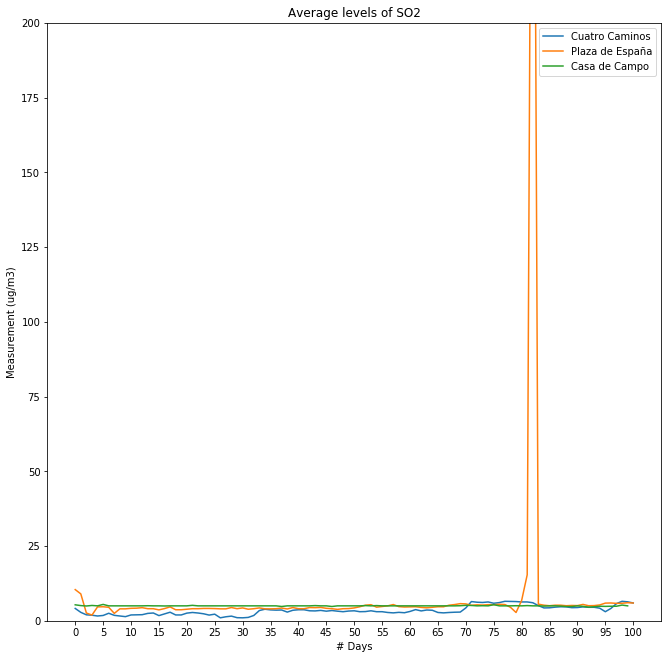



Sample: NO2


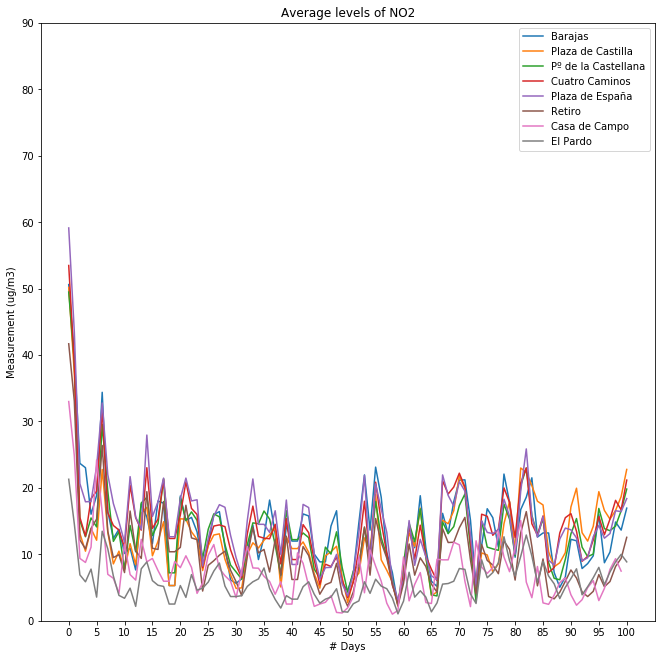



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


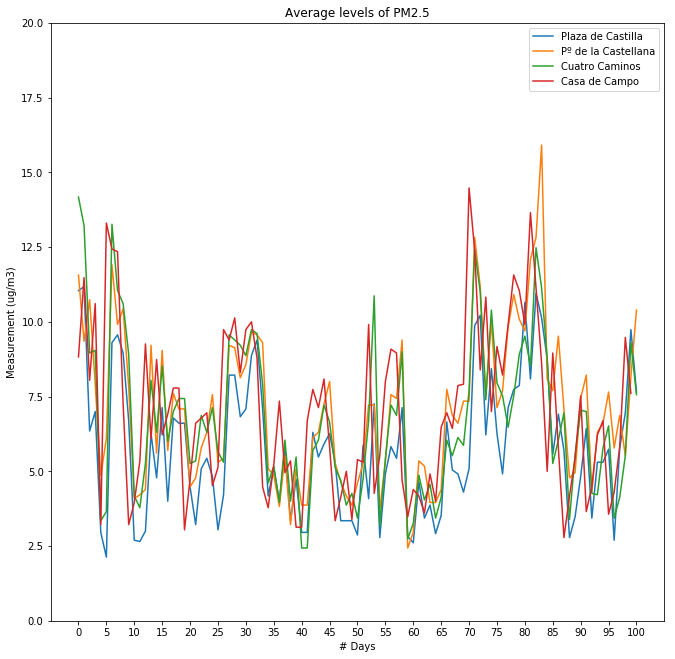



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


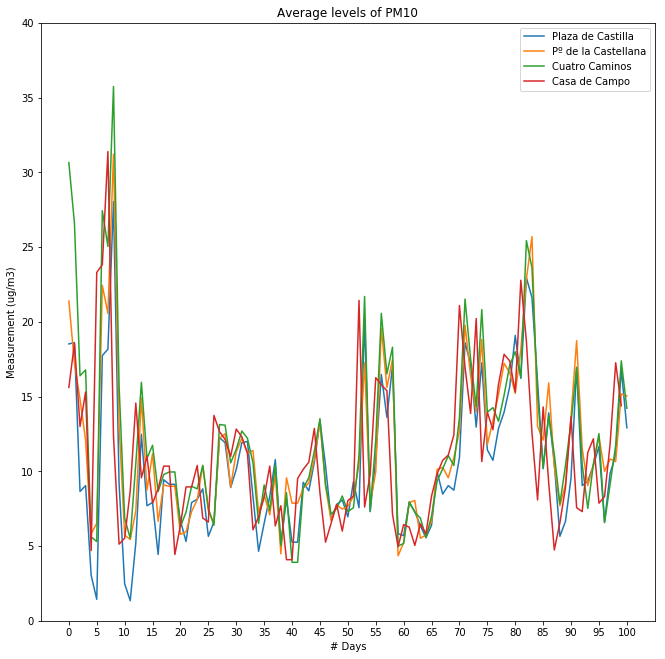



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


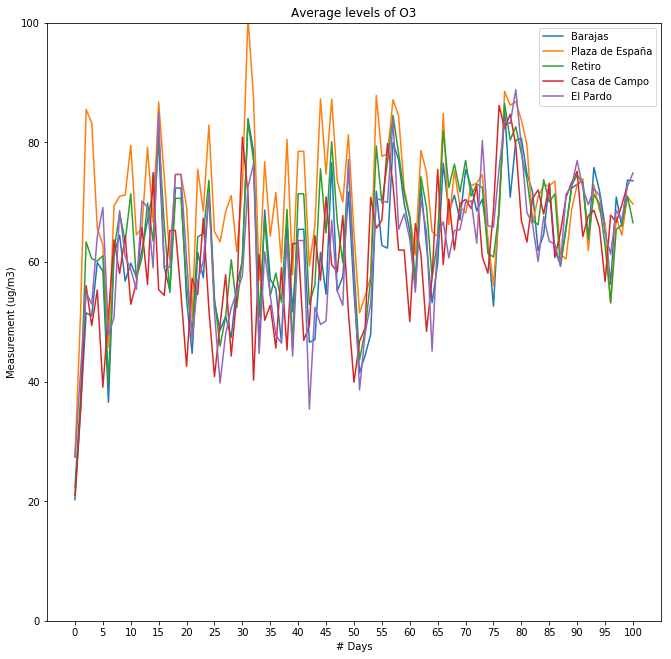

In [4]:
# Plotting the average value for each day
matplotlib.rcParams['figure.figsize'] = (11, 11)

for m_code,m_name in measurements.items():
    days_m = []
    places = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        if df.shape[0] != 0:
            # Get the total days
            df.sort_values(['MES','DIA'])
            df = df.reset_index()
            df['NUMDIA'] = df.index
            days_m = df['NUMDIA'].copy()
            
            all_times = df[check_times].copy()
            for t in check_times:
                all_times[t] = pd.to_numeric(all_times[t])
            all_times['MEDIO'] = all_times.mean(axis=1)
            plt.plot(df['NUMDIA'],all_times['MEDIO'])
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(places)>0:
        plt.legend(places)
        plt.xticks(days)
        plt.xlabel('# Days')
        plt.ylabel('Measurement ({})'.format(units[m_name]))
        plt.title('Average levels of '+m_name)
        ax = plt.gca()
        ax.set_ylim(0,bands[m_name]['Fair'][1]) # Setting the 'moderate' upper limit
        plt.xticks(days[::5], days[::5])
        plt.show()



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


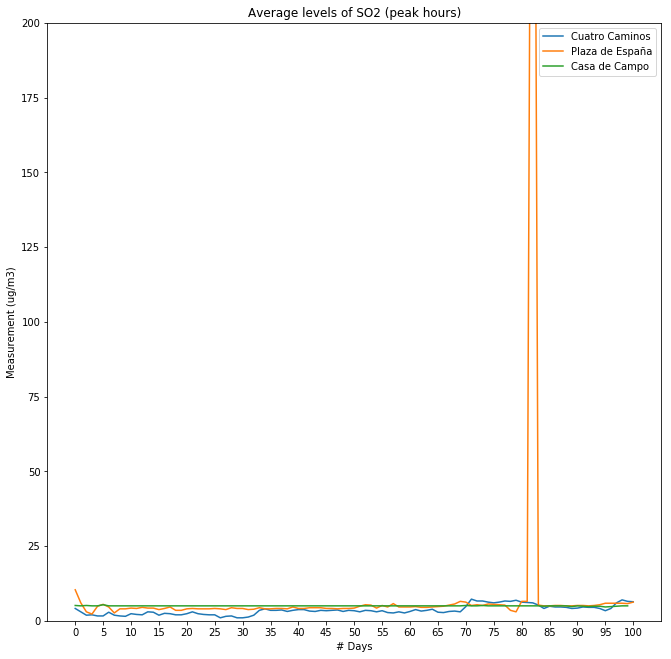



Sample: NO2


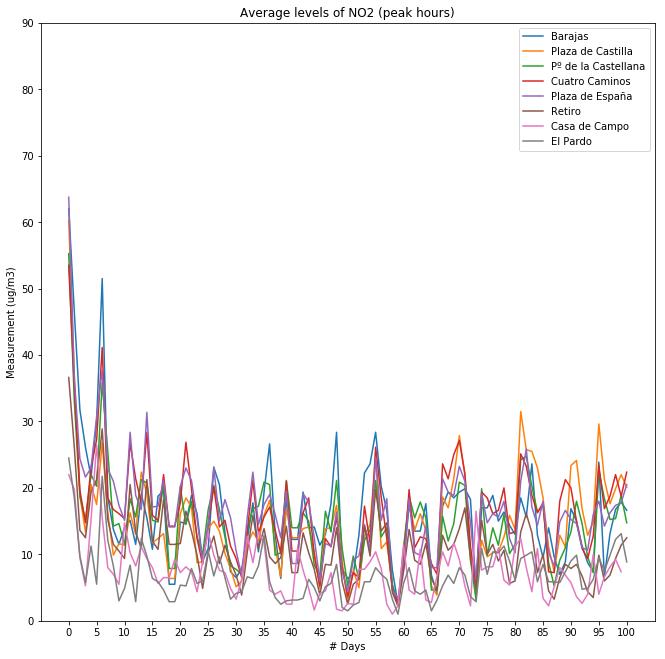



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


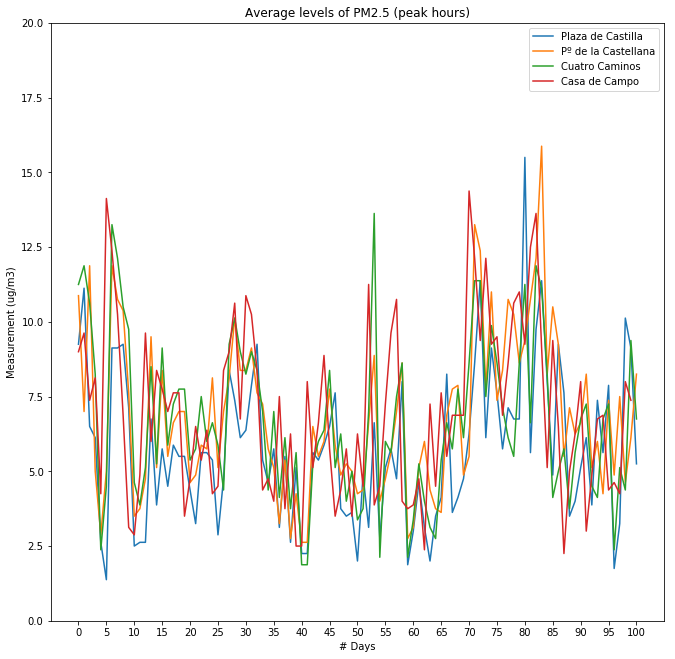



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


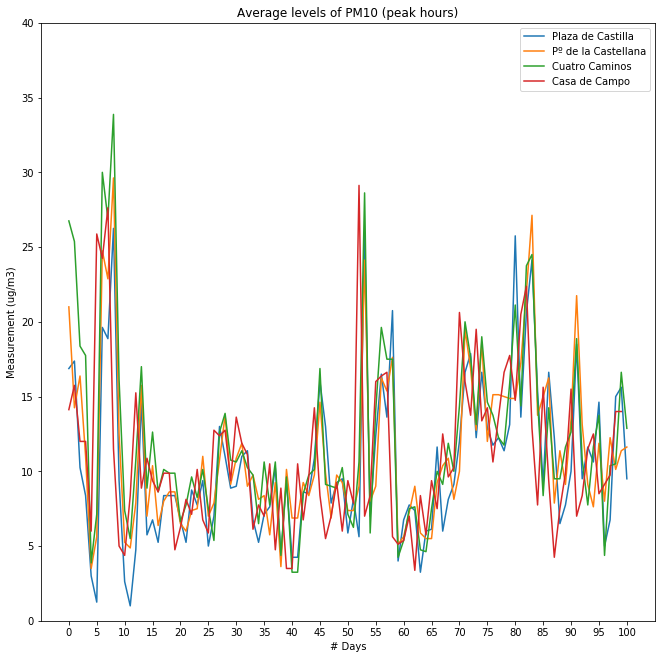



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


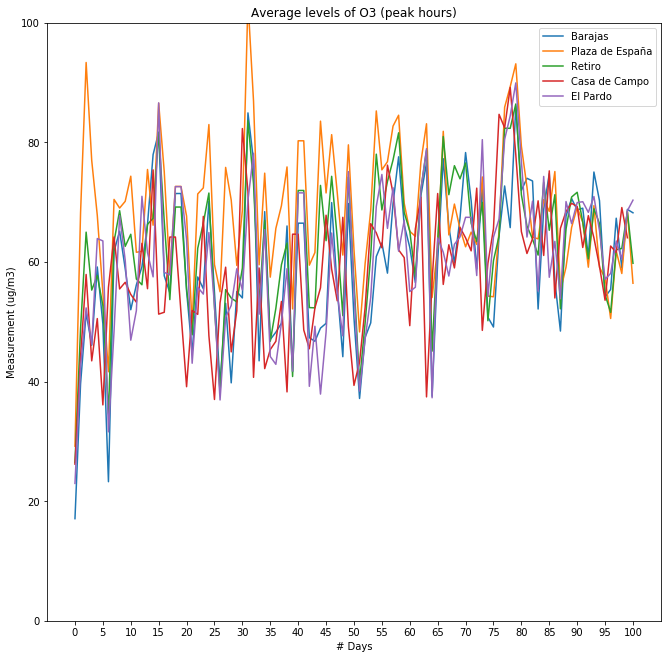

In [5]:
# Plotting the average value for each day DURING PEAK TIMES
matplotlib.rcParams['figure.figsize'] = (11, 11)

for m_code,m_name in measurements.items():
    days_m = []
    places = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        if df.shape[0] != 0:
            # Get the number of days
            df.sort_values(['MES','DIA'])
            df = df.reset_index()
            df['NUMDIA'] = df.index
            days_m = df['NUMDIA'].copy()
            
            all_times = df[check_times_peak].copy()
            for t in check_times_peak:
                all_times[t] = pd.to_numeric(all_times[t])
            all_times['MEDIO'] = all_times.mean(axis=1)
            plt.plot(df['NUMDIA'],all_times['MEDIO'])
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(places)>0:
        plt.legend(places)
        plt.xticks(days)        
        plt.xlabel('# Days')
        plt.ylabel('Measurement ({})'.format(units[m_name]))
        plt.title('Average levels of ' + m_name + ' (peak hours)')
        ax = plt.gca()
        ax.set_ylim(0,bands[m_name]['Fair'][1]) # Setting the 'moderate' upper limit
        plt.xticks(days[::5], days[::5])
        plt.show()

### Improving the visualisation

As we can see there is a lot of oscillation. In order to make the graphs 'cleaner' I am using *Exponentially Weighted Moving Average*, also known as EMA. You can find the math behind it [here](https://en.wikipedia.org/wiki/Moving_average). We will apply EMA to air data during peak times and midday.



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


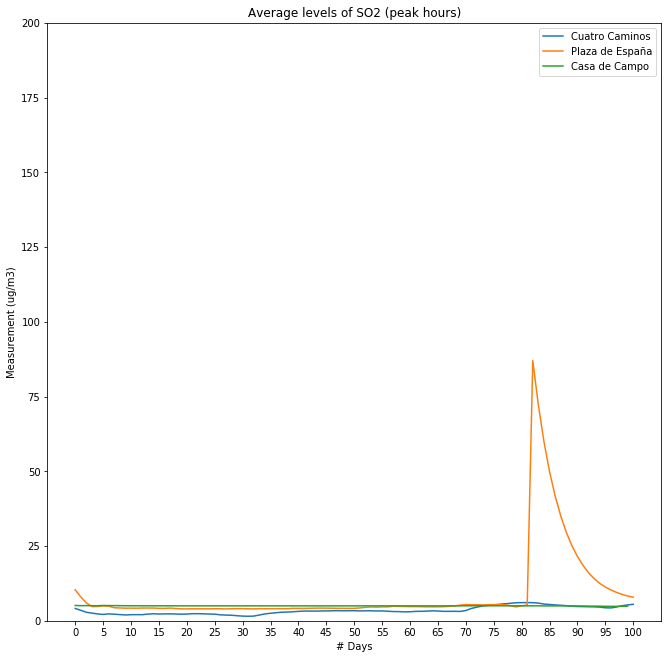



Sample: NO2


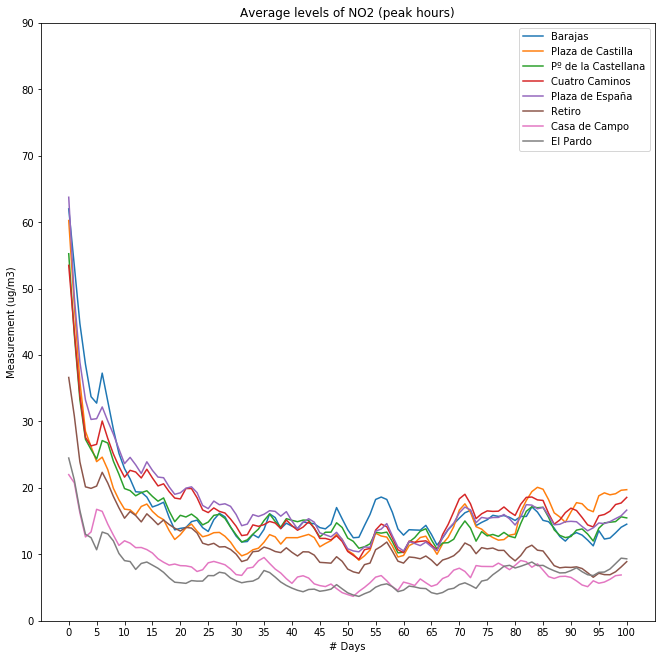



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


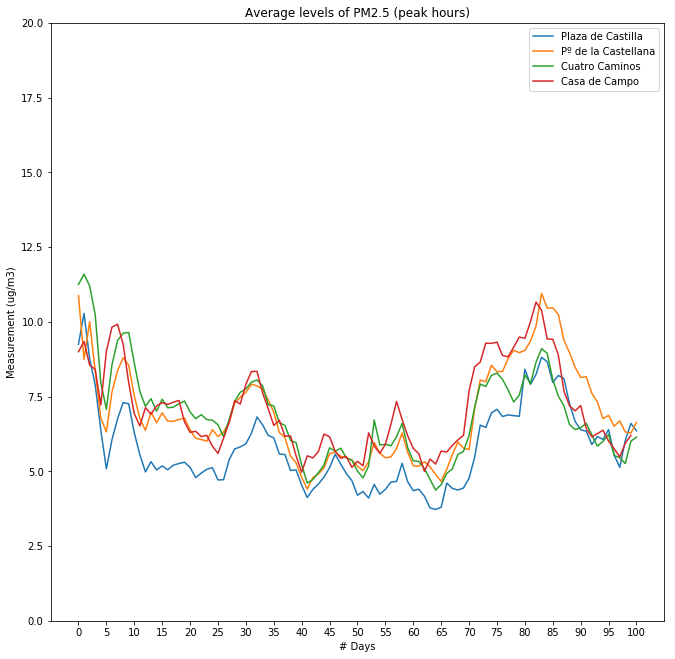



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


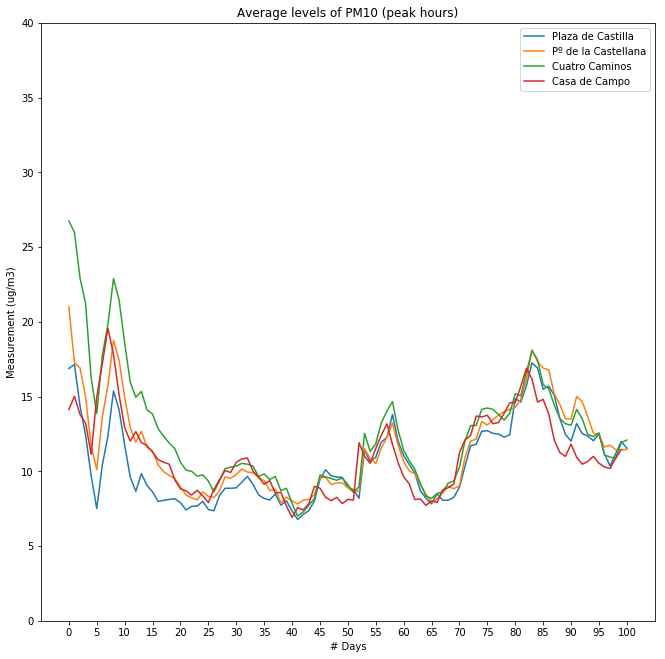



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


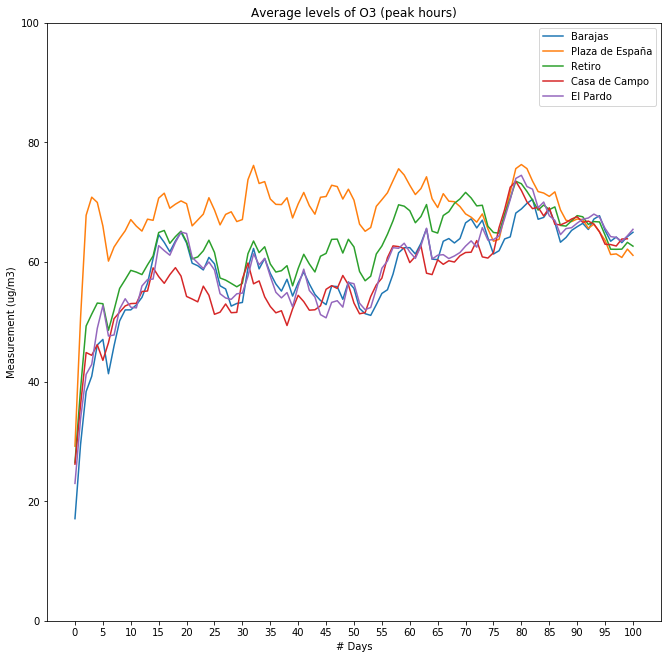

In [6]:
# Plotting the average value for each day DURING PEAK TIMES
# Using Exponentially Weighted Moving Average (EMA)

matplotlib.rcParams['figure.figsize'] = (11, 11)

for m_code,m_name in measurements.items():
    days_m = []
    places = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        if df.shape[0] != 0:
            # Get the number of days
            df.sort_values(['MES','DIA'])
            df = df.reset_index()
            df['NUMDIA'] = df.index
            days_m = df['NUMDIA'].copy()
            
            all_times = df[check_times_peak].copy()
            for t in check_times_peak:
                all_times[t] = pd.to_numeric(all_times[t])
            all_times['MEDIO'] = all_times.mean(axis=1)
            all_times_ema = all_times['MEDIO'].ewm(span=10).mean()
            plt.plot(days_m,all_times_ema)
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(places)>0:
        plt.legend(places)
        plt.xticks(days)        
        plt.xlabel('# Days')
        plt.ylabel('Measurement ({})'.format(units[m_name]))
        plt.title('Average levels of ' + m_name + ' (peak hours)')
        ax = plt.gca()
        ax.set_ylim(0,bands[m_name]['Fair'][1]) # Setting the 'moderate' upper limit
        plt.xticks(days[::5], days[::5])
        plt.show()



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


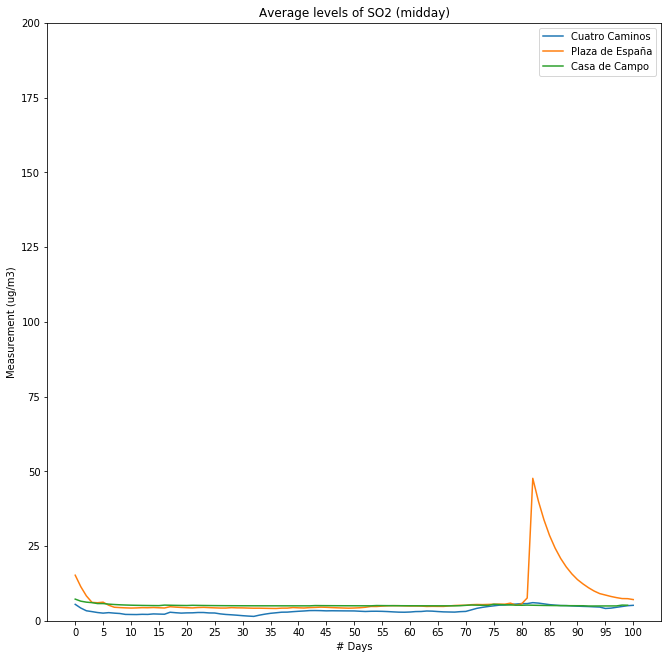



Sample: NO2


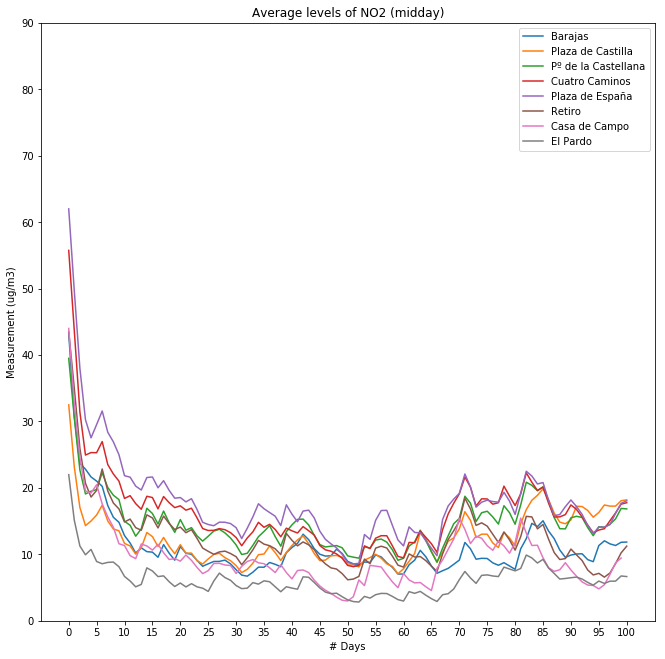



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


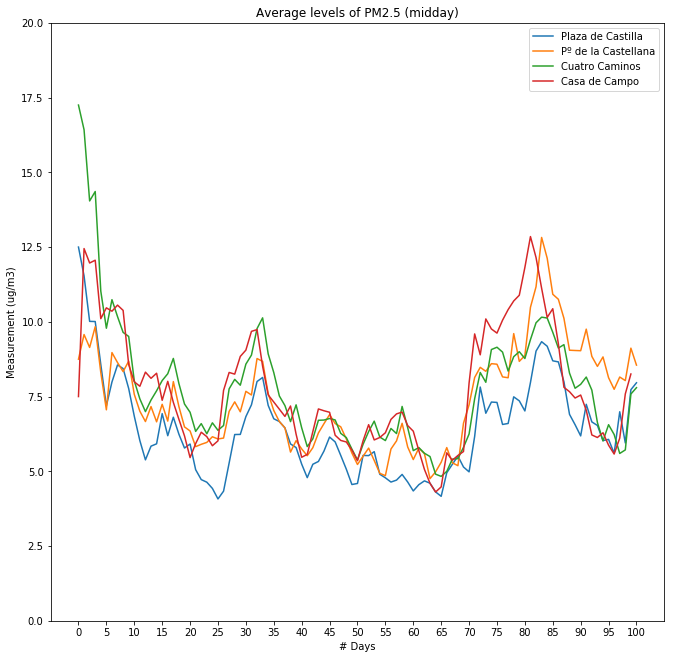



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


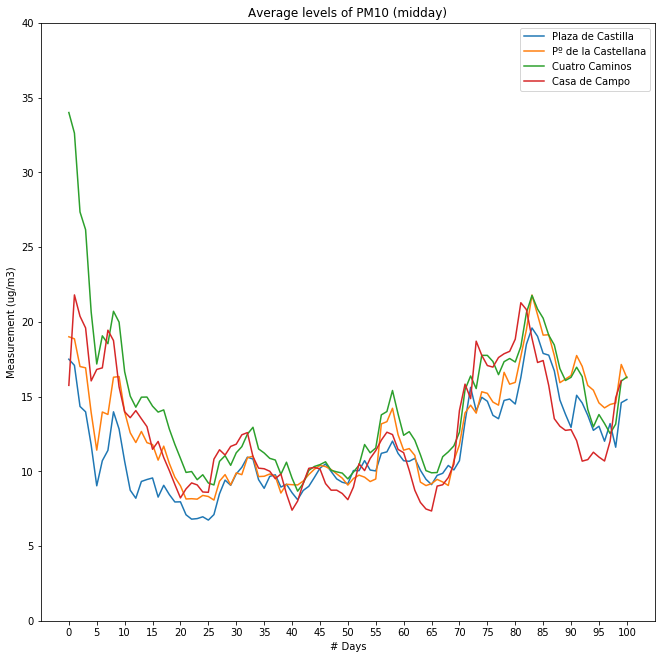



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


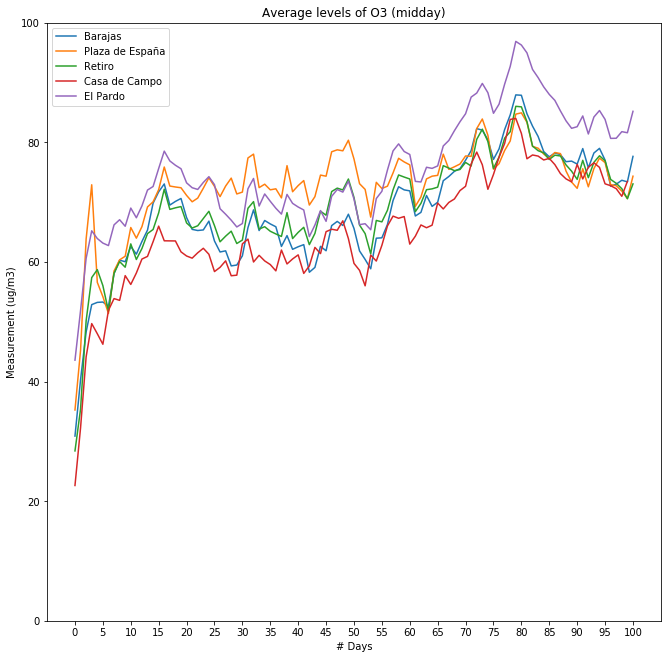

In [7]:
# Plotting the average value for each day DURING MIDDAY
# Using Exponentially Weighted Moving Average (EMA)

matplotlib.rcParams['figure.figsize'] = (11, 11)

for m_code,m_name in measurements.items():
    days_m = []
    places = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        if df.shape[0] != 0:
            # Get the number of days
            df.sort_values(['MES','DIA'])
            df = df.reset_index()
            df['NUMDIA'] = df.index
            days_m = df['NUMDIA'].copy()
            
            all_times = df[check_times_mid].copy()
            for t in check_times_mid:
                all_times[t] = pd.to_numeric(all_times[t])
            all_times['MEDIO'] = all_times.mean(axis=1)
            all_times_ema = all_times['MEDIO'].ewm(span=10).mean()
            plt.plot(days_m,all_times_ema)
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(places)>0:
        plt.legend(places)
        plt.xticks(days)        
        plt.xlabel('# Days')
        plt.ylabel('Measurement ({})'.format(units[m_name]))
        plt.title('Average levels of ' + m_name + ' (midday)')
        ax = plt.gca()
        ax.set_ylim(0,bands[m_name]['Fair'][1]) # Setting the 'moderate' upper limit
        plt.xticks(days[::5], days[::5])
        plt.show()

### Air quality per month

One of the things I love about Pandas is that you can use functions that resemble SQL functions and syntax. We will now group data by month and location. Let's see the evolution of pollution since March during midday and peak times.



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


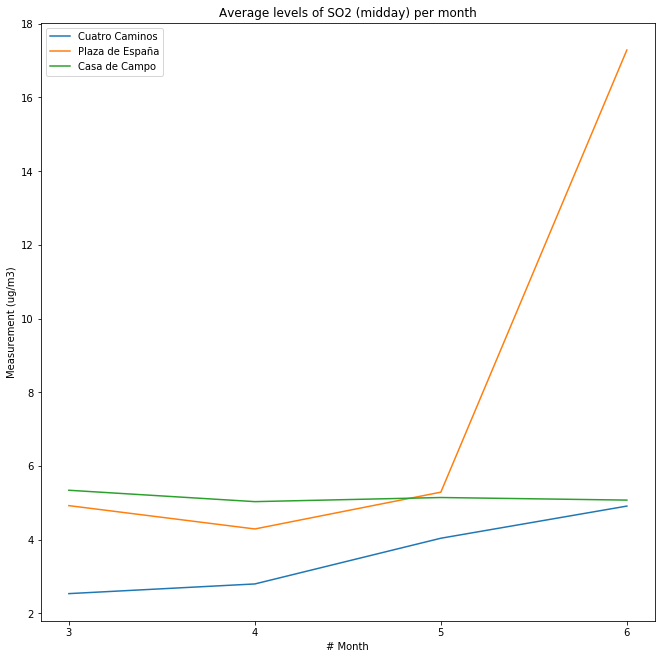



Sample: NO2


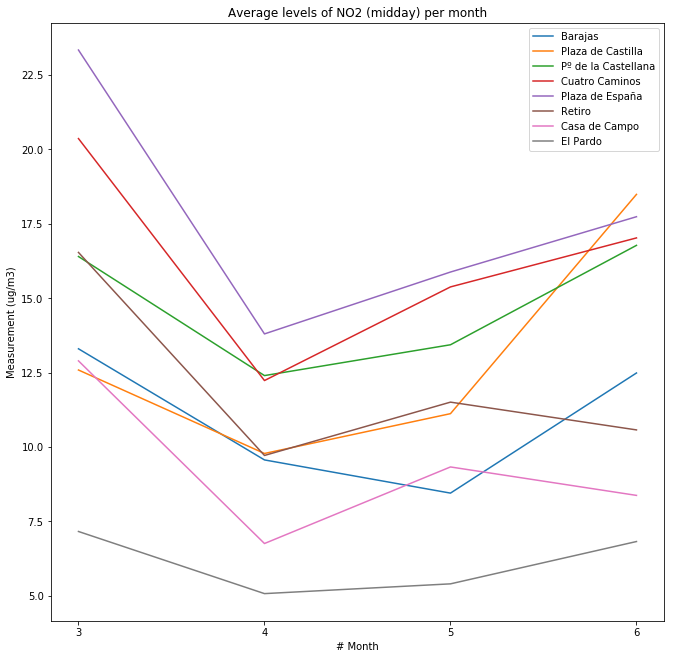



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


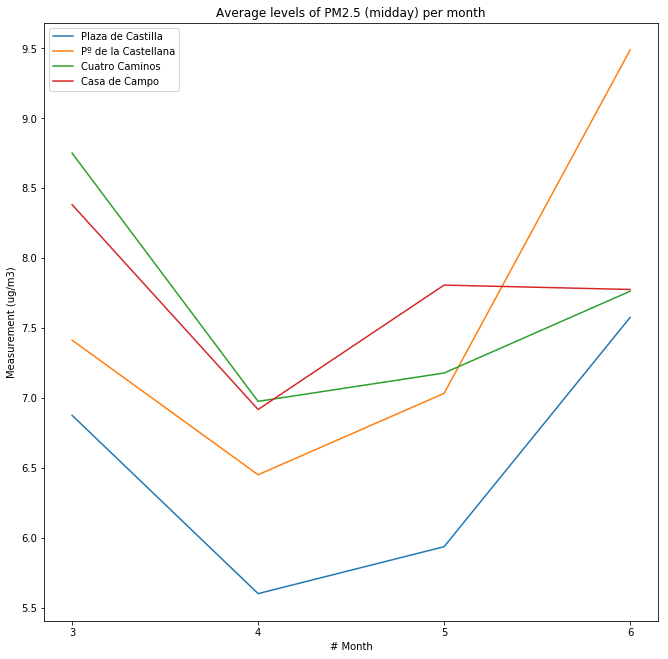



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


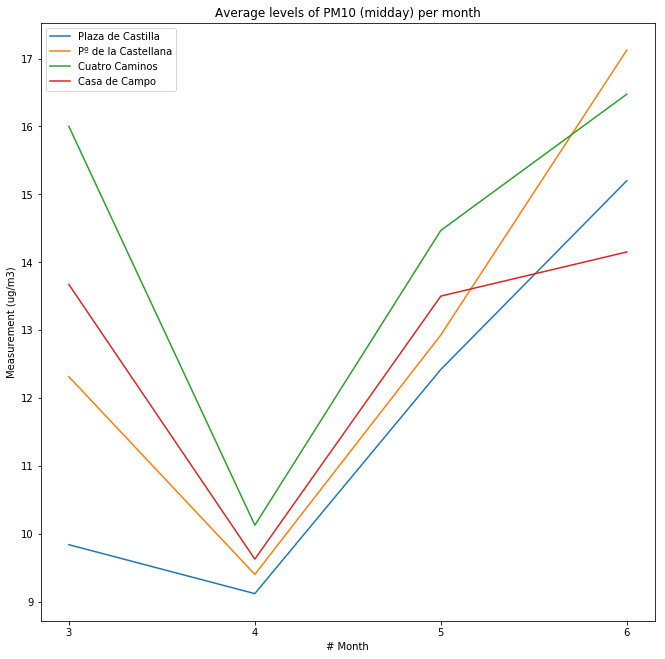



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


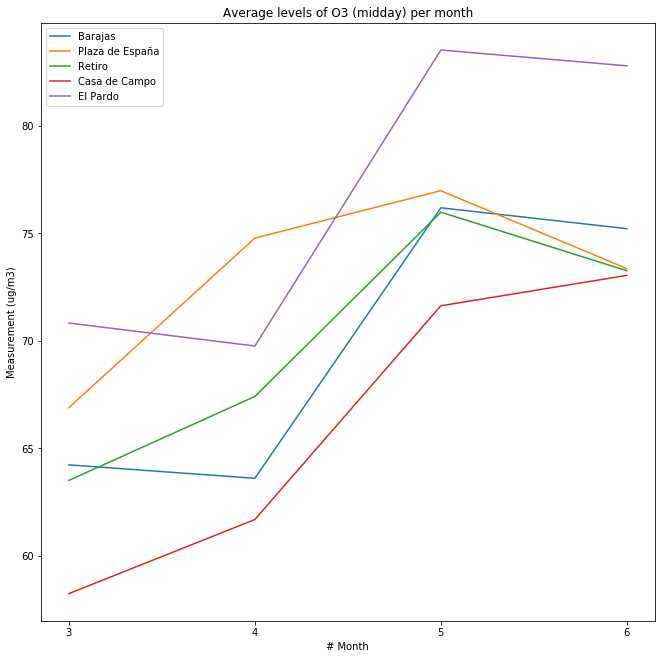

In [8]:
# Plotting the average value for each day DURING MIDDAY

matplotlib.rcParams['figure.figsize'] = (11, 11)


all_data['MEDIO']= all_data[check_times_mid].mean(axis=1)

for m_code,m_name in measurements.items():
    places = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        # All the data for that sample and location
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        if df.shape[0] != 0:
            months = df['MES'].unique()
            air_data_monthly = df.groupby('MES')['MEDIO'].mean()
            plt.plot(months,air_data_monthly)
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(places)>0:
#         print(months)
        plt.legend(places)
        plt.xticks(range(min(months),max(months)+1))        
        plt.xlabel('# Month')
        plt.ylabel('Measurement ({})'.format(units[m_name]))
        plt.title('Average levels of ' + m_name + ' (midday) per month')
        plt.show()



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


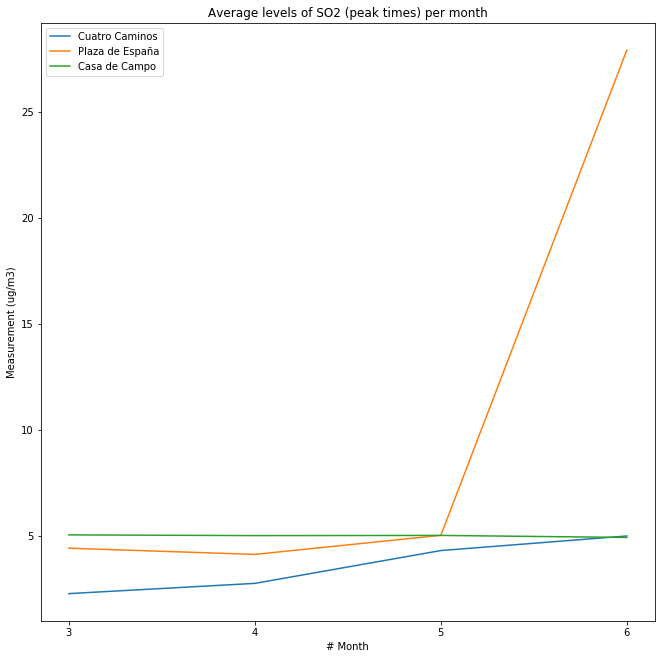



Sample: NO2


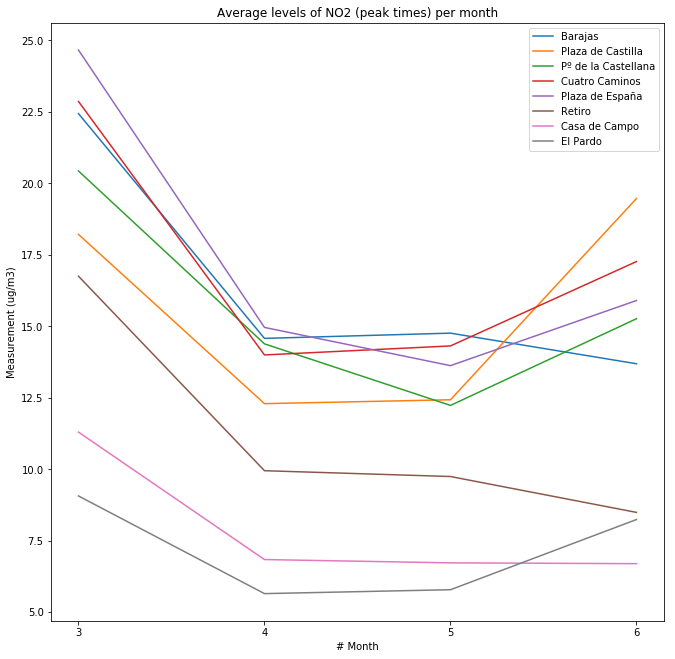



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


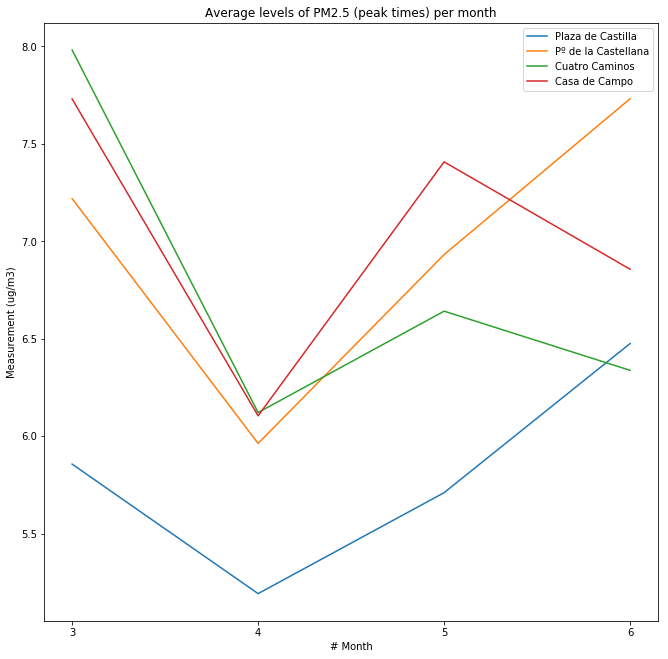



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


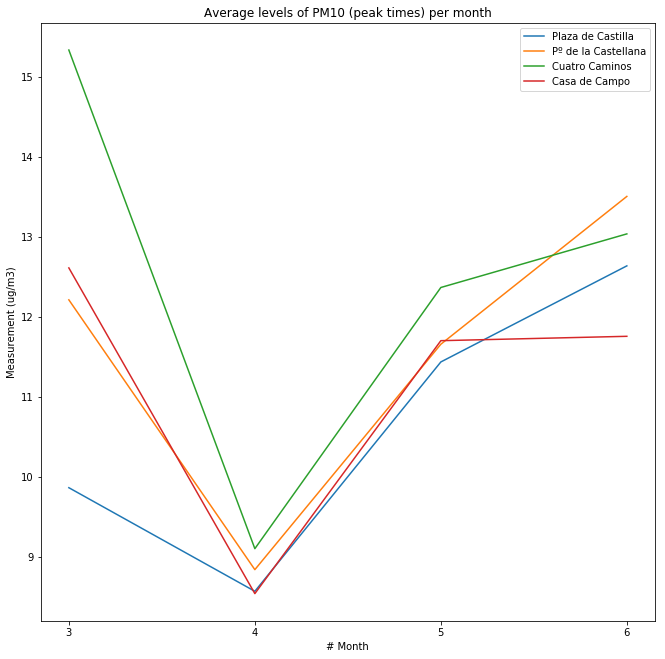



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


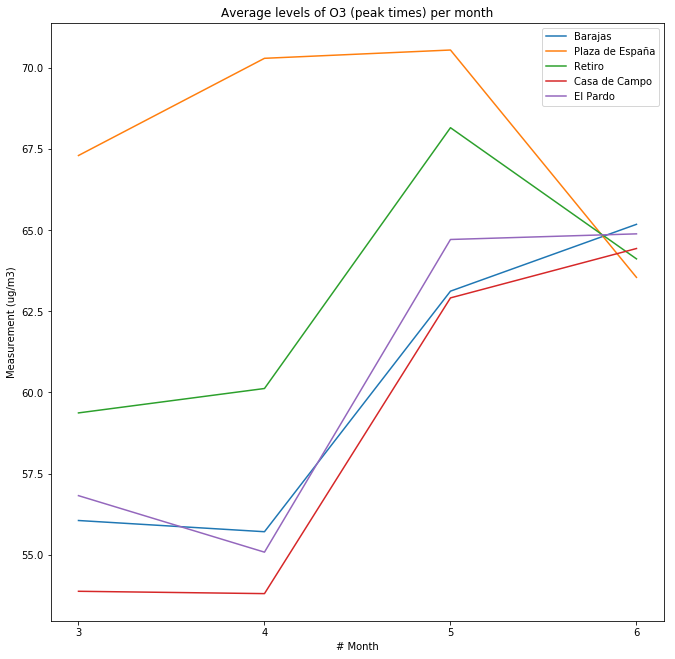

In [9]:
# Plotting the average value for each day DURING PEAK TIMES

matplotlib.rcParams['figure.figsize'] = (11, 11)


all_data['MEDIO-PUNTA']= all_data[check_times_peak].mean(axis=1)

for m_code,m_name in measurements.items():
    places = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        # All the data for that sample and location
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        if df.shape[0] != 0:
            months = df['MES'].unique()
            air_data_monthly = df.groupby('MES')['MEDIO-PUNTA'].mean()
            plt.plot(months,air_data_monthly)
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(places)>0:
#         print(months)
        plt.legend(places)
        plt.xticks(range(min(months),max(months)+1))        
        plt.xlabel('# Month')
        plt.ylabel('Measurement ({})'.format(units[m_name]))
        plt.title('Average levels of ' + m_name + ' (peak times) per month')
        plt.show()

### Fiddling with heat maps

I can't hide my Image Processing background, so let's play with matrices a little bit...



Sample: SO2
[Barajas]: No data for this sample and location
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


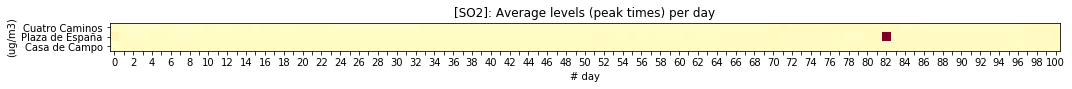



Sample: NO2


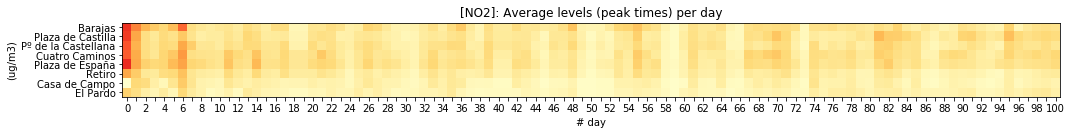



Sample: PM2.5
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


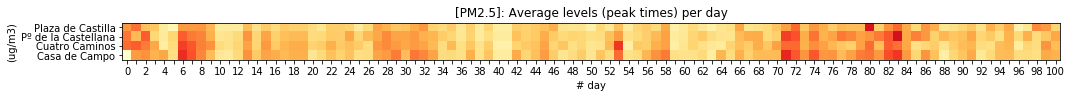



Sample: PM10
[Barajas]: No data for this sample and location
[Plaza de España]: No data for this sample and location
[Retiro]: No data for this sample and location
[El Pardo]: No data for this sample and location


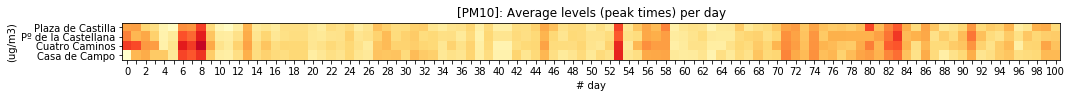



Sample: O3
[Plaza de Castilla]: No data for this sample and location
[Pº de la Castellana]: No data for this sample and location
[Cuatro Caminos]: No data for this sample and location


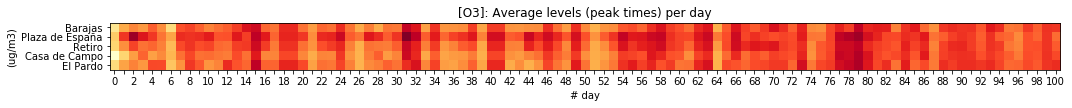

In [10]:
# Plotting the average value for each day DURING PEAK TIMES

matplotlib.rcParams['figure.figsize'] = (15, 30)


all_data['MEDIO-PUNTA']= all_data[check_times_peak].mean(axis=1)

for m_code,m_name in measurements.items():
    days = len(files)
    places = []
    data = []
    print('\n\nSample: ' + m_name)
    for code, location in check_places.items():
        # All the data for that sample and location
        df = all_data.loc[(all_data['MAGNITUD']==m_code) & (all_data['PUNTO_MUESTREO'].str.contains(code))].copy()
        
        
        if df.shape[0] != 0:
            air_data_daily = list(df['MEDIO-PUNTA'].values)
            while len(air_data_daily)<days:
                air_data_daily.insert(0,0)
#             print(len(air_data_daily))
            data.append(air_data_daily)
            places.append(location)
        else:
            print('[{}]: No data for this sample and location'.format(location))
    
    if len(data)>0:
        air_data_np = np.array(data)
        im = plt.imshow(air_data_np, vmin=0, vmax=bands[m_name]['Fair'][1])
        plt.set_cmap('YlOrRd') # Yellow = low / Red = high
        plt.xticks(range(days))
        plt.yticks(range(air_data_np.shape[0]),places)
        plt.title(m_name)
        plt.ylabel('({})'.format(units[m_name]))
        plt.xlabel('# day')
        ax = plt.gca()
#         ax.set_anchor('W')
        for label in ax.get_xaxis().get_ticklabels()[1::2]:
            label.set_visible(False)
        plt.tight_layout()
        plt.title('[{}]: Average levels (peak times) per day'.format(m_name))
        plt.show()


